# Walks through the sensor graph: which routes a prediction took

**Explanation notebook 3 in `notebooks/xai/`.** `notebooks/README.md` says how every notebook is laid out, and `notebooks/xai/README.md` says what every explanation notebook shares. Read `01_shap_fd001.ipynb` first: this notebook sets its method beside Shapley values, and uses its words.

## What this notebook is for

Shapley values and occlusion say **which sensors'** readings moved a prediction. They cannot say **how** the readings reached it: whether a sensor mattered at its own place in the graph, or because the graph layers mixed its reading into its neighbours and it was used there. The paper says its graph matters, and describes "edge weights" in its interpretability graphs, so that second question matters too.

**Walks** answer it. The method, GNN-LRP (Schnake et al., 2022), reads the trained network's own weights and splits one prediction exactly into shares, one per route through the sensor graph. It is **not in the paper** (assumption A-29).

## What it does not do

- **It does not train anything.** It loads the same stored network the other two notebooks explain.
- **It does not say whether the paper's graph is good.** It reads one trained network. Whether the graph helps needs networks trained on other graphs (assumption A-27).
- **It does not give cycles.** Its shares are parts of the network's score before its last step, for reasons section 1 gives.
- **It does not say what wears an engine**, for the same reasons the Shapley notebook gives.

## The notebook in one list

| # | Step | What goes in | What comes out |
|---|------|--------------|----------------|
| 1 | **Load** the trained network | the stored five-seed run | seed 42's network and its data, checked against the run |
| 2 | **Split one window into walks** | the window the other notebooks work through | 38,416 walk shares, checked three ways, and the largest |
| 3 | **Follow the same engine's life** | every window of that engine | what stays and what moves, and what flowed along each connection |
| 4 | **Set flow beside removal** | the same windows | what removing each connection does, and whether it matches the flow |
| 5 | **Read the five-seed measurement** | the stored `walks/` folders | trained networks beside their own untrained starting points |

## 1. Background

### What one graph layer does

Each of the network's three graph layers gives every sensor a new set of numbers made from its neighbours' current numbers:

```
new_i = ReLU( sum over sensors j of  A_hat[i, j] * old_j * W )
```

`A_hat[i, j]` is zero unless sensor `j` is joined to sensor `i` in the paper's graph or is `i` itself; each row adds up to 1. `W` is the layer's learned weight table, and `ReLU` turns anything negative into zero. After one layer a sensor holds a mix of its neighbours; after three, readings from up to three steps away.

### What a walk is

A **walk** is the list of sensors one piece of a reading passes through, one per layer: `T50 -> T30 -> T30 -> Ps30` is T50's reading, carried into T30 by the first layer, kept at T30 by the second, carried into Ps30 by the third. With 14 sensors and three layers there are 14 × 14 × 14 × 14 = 38,416 possible walks; the paper's graph allows 5,178 of them, and the rest carry exactly zero.

### Why one prediction splits exactly into walks

The network's last step turns a number, the **score**, into a prediction with `125 / (1 + e^-score)`, the sigmoid. For one window, every ReLU is either on (passes its input) or off (passes zero). Holding that pattern, everything between the numbers entering the graph layers and the score is multiplication and addition, so the score multiplies out into a sum of products, one per walk, plus a **constant** from the network's two last layers that belongs to no sensor. The graph layers add no constant of their own (assumption A-12), which is why nothing else is left over.

The sigmoid itself bends, so shares of the score cannot be turned into cycles that still add up. The shares are therefore **parts of the score, not cycles**: a score of 0 is a prediction of 62.5 cycles, higher scores predict more.

### A small example

`explain/README.md` works one through by hand on three real sensors: in a toy network with one graph layer, test engine 5's T50 reading of 0.8176 sends `0.8176 × 1/3 = 0.2725` of the score along the walk T50 -> T30, and five such walks plus the constant 0.5 give exactly the score 0.2202. `tests/test_examples_torch.py` checks every number.

### Three groups the graph cannot tell apart

In the paper's graph, P15, Nf, NRf and BPR are joined to exactly the same sensors, and so are P30 and Ps30, and Nc and W31 (finding F-18). From the first graph layer on, each group's members hold the same numbers, and where a walk ends among them is decided by the network's random starting weights. This notebook counts each group as one sensor wherever a walk ends.

**Do not confuse** a walk's share with a Shapley value: the Shapley value is in cycles, measured against a typical engine by running the network 16,384 times; a walk share is part of the score, read off the weights with nothing replaced. Their rankings can be compared; their sizes cannot.

## 2. Setup

The same imports, and the same stored run, as the other two notebooks: the most recent five-seed run of `config/fd001.yaml` with the paper's graph, the last-cycle temporal stage and the network sizes of Table 4, whose trained networks were saved.

In [1]:
from __future__ import annotations

import json
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

PROJECT_ROOT = next(
    folder for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "pyproject.toml").is_file()
)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

try:
    import torch
except ImportError as missing:
    raise ImportError(
        "This notebook runs a trained network, which needs PyTorch, and PyTorch is "
        'not installed. Install the project with  pip install -e ".[model]"'
    ) from missing

from thesis_gnn_rul_xai.config import load_config
from thesis_gnn_rul_xai.explain import (
    connection_relevance,
    connection_removal,
    connections_of,
    conservation_error,
    crossing_relevance,
    indistinguishable_sensors,
    mean_window_baseline,
    node_relevance,
    shap_values,
    top_walks,
    walk_relevance,
)
from thesis_gnn_rul_xai.graph.adjacency import to_networkx
from thesis_gnn_rul_xai.models import ModelConfig
from thesis_gnn_rul_xai.training import evaluate_model, find_runs, load_seed
from thesis_gnn_rul_xai.utils.logging_setup import configure_logging

configure_logging(logging.ERROR)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
print(f"Project root: {PROJECT_ROOT}")
print(f"PyTorch     : {torch.__version__}")

Project root: D:\Main\University\Thesis\Code\Thesis GNN RUL XAI
PyTorch     : 2.13.0+cpu


In [2]:
config = load_config(PROJECT_ROOT / "config" / "fd001.yaml")
runs = [
    run for run in find_runs(
        preprocessing=config, seeds=5, with_weights=True, split="varies_with_seed",
        early_stopping=True, lr_schedule="step", temporal_stage="last_cycle",
    )
    if run.model_config == ModelConfig()
]
if not runs:
    raise FileNotFoundError(
        "reports/ holds no five-seed run of config/fd001.yaml that saved its trained "
        "networks. Make one with\n\n"
        "    python scripts/train.py --config config/fd001.yaml --seeds 5\n\n"
        "and run this notebook again."
    )
run = runs[-1]
SEED = 42
print(f"Stored run : {run.name}")
print(f"Commit     : {run.summary['commit']}")

Stored run : fd001_physics_row_cap_5seed_varsplit_cfgba82e3_5602773-dirty_20260914T233911Z
Commit     : 5602773-dirty


## 3. The trained network

### Step 1 — Load the trained network

**What.** Load seed 42's network and rebuild its data, as the other notebooks do.

**Check.** The loaded network must score the test engines exactly as the run recorded.

In [3]:
model, prepared = load_seed(run, SEED)
sensors = list(prepared.sensor_symbols)
groups = indistinguishable_sensors(model, sensors)

recorded = float(run.results.set_index("seed").loc[SEED, "rmse"])
scored = evaluate_model(model, prepared.test)["rmse"]
same_network = bool(np.isclose(scored, recorded, rtol=0, atol=1e-6))
assert same_network
print(f"OK  test RMSE {scored:.6f} cycles, as the run recorded for seed {SEED}.")
print("    sensors the graph cannot tell apart:", "; ".join(", ".join(g) for g in groups))

OK  test RMSE 16.694915 cycles, as the run recorded for seed 42.
    sensors the graph cannot tell apart: P15, Nf, NRf, BPR; P30, Ps30; Nc, W31


## 4. The explanation, step by step

### Step 2 — One window, split into walks

**What.** Take the window the other notebooks work through: the last window of the held-back engine with the most windows, close to that engine's failure. Split its score into walks.

**Why.** One window is small enough to check completely: the shares must add up to the score, each sensor's total must equal what PyTorch's own differentiation gives, and the score must turn into the network's own prediction.

In [4]:
held_back = prepared.validation
units, counts = np.unique(held_back.units, return_counts=True)
engine = int(units[np.argmax(counts)])
engine_rows = np.flatnonzero(held_back.units == engine)
engine_rows = engine_rows[np.argsort(held_back.end_cycles[engine_rows])]
window = held_back.features[engine_rows[-1]]

result = walk_relevance(model, window)
walks_sum = float(result.relevance.sum())
print(f"Engine {engine}, window ending at cycle {held_back.end_cycles[engine_rows[-1]]}")
print(f"  prediction                     {result.predicted[0]:9.3f} cycles")
print(f"  score before the sigmoid       {result.score[0]:+9.4f}")
print(f"  walks added up                 {walks_sum:+9.4f}")
print(f"  constant, belonging to no sensor {result.constant[0]:+7.4f}")
print(f"  walks + constant - score       {walks_sum + result.constant[0] - result.score[0]:+9.1e}")
print(f"  walks that are not zero        {int((result.relevance[0] != 0).sum()):,} of {result.relevance[0].size:,}")

Engine 5, window ending at cycle 269
  prediction                         4.596 cycles
  score before the sigmoid         -3.2658
  walks added up                   -4.0130
  constant, belonging to no sensor +0.7472
  walks + constant - score        +4.4e-16
  walks that are not zero        5,178 of 38,416


**Check.** Walks plus constant must give back the score, and each sensor's total, over the walks that start at it, must equal its number times how fast the score changes with it — computed here by PyTorch's own differentiation, which shares no code with the walks.

In [5]:
adds_up = conservation_error(result) < 1e-9

double = load_seed(run, SEED)[0].double()
nodes = double.temporal(torch.from_numpy(window[None].astype(np.float64))).detach().requires_grad_(True)
hidden = nodes
for layer in double.graph_layers:
    hidden = torch.relu(layer(hidden, double.adjacency))
double.fc2(torch.relu(double.fc1(torch.flatten(hidden, start_dim=1)))).sum().backward()
by_gradient = (nodes.grad * nodes).sum(dim=2).detach().numpy()[0]
matches_gradient = bool(np.allclose(node_relevance(result)[0], by_gradient, atol=1e-9))
turns_into_prediction = bool(np.isclose(125 / (1 + np.exp(-result.score[0])), result.predicted[0], atol=1e-3))
assert adds_up and matches_gradient and turns_into_prediction
print(f"OK  walks + constant = score, to {conservation_error(result):.1e}")
print("OK  each sensor's total equals its number times the score's derivative")
print("OK  the score through the sigmoid is the network's own prediction")

OK  walks + constant = score, to 4.4e-16
OK  each sensor's total equals its number times the score's derivative
OK  the score through the sigmoid is the network's own prediction


The twelve walks that carry the most on this window, with the groups the graph cannot tell apart counted as one wherever a walk ends, beside the size of every walk added up ignoring its sign:

In [6]:
largest = top_walks(result, sensors, count=12, pool=groups)
display(largest.round(4))
parts = crossing_relevance(result, sensors, pool=groups)
ratio = float(parts["absolute_total"].iloc[0] / abs(parts["stays"].iloc[0] + parts["moves"].iloc[0]))
print(f"Every walk's size added up is {ratio:.1f} times the size of their sum on this window.")

,walk,mean,mean_abs
0,BPR -> P15/Nf/NRf/BPR -> P15/Nf/NRf/BPR -> P15...,-0.5046,0.5046
1,T24 -> P15/Nf/NRf/BPR -> P15/Nf/NRf/BPR -> P15...,-0.4696,0.4696
2,Nf -> P15/Nf/NRf/BPR -> P15/Nf/NRf/BPR -> P15/...,-0.2117,0.2117
3,NRf -> P15/Nf/NRf/BPR -> P15/Nf/NRf/BPR -> P15...,-0.1820,0.1820
4,Ps30 -> T24 -> P15/Nf/NRf/BPR -> P15/Nf/NRf/BPR,-0.0883,0.0883
5,P30 -> T24 -> P15/Nf/NRf/BPR -> P15/Nf/NRf/BPR,0.0797,0.0797
6,T30 -> T24 -> P15/Nf/NRf/BPR -> P15/Nf/NRf/BPR,-0.0791,0.0791
7,BPR -> T24 -> P15/Nf/NRf/BPR -> P15/Nf/NRf/BPR,-0.0788,0.0788
8,BPR -> P15/Nf/NRf/BPR -> T24 -> P15/Nf/NRf/BPR,-0.0788,0.0788
9,T24 -> T24 -> P15/Nf/NRf/BPR -> P15/Nf/NRf/BPR,-0.0734,0.0734


Every walk's size added up is 3.8 times the size of their sum on this window.


#### Reading the table

On this window, close to the engine's failure (a prediction of 4.596 cycles), the four largest walks all end inside the group P15, Nf, NRf and BPR and all pull the score down: the walk starting at BPR by −0.5046, at T24 by −0.4696, at Nf by −0.2117 and at NRf by −0.1820, in score units. The group's members hold the same numbers from the first graph layer on, so these four are one route read from four starting readings. The first walk that reaches the other side of the graph comes twelfth: `Nc -> P30/Ps30 -> Nc/W31 -> W32`, −0.0526. Ignoring signs, the walks add up to 3.8 times the size of their sum on this window.

Section 1's warning applies: a list of large walks read on its own shows mostly cancellation.

### Step 3 — The same engine's whole life

**What.** Split every window of the engine into walks, and follow three things over its life: the walks that stay within their starting sensor's group, the walks that move between groups, and the constant; and, on the sensor graph, what flowed along each connection, averaged over the whole life.

**Why.** One window can mislead; the whole life shows what is steady.

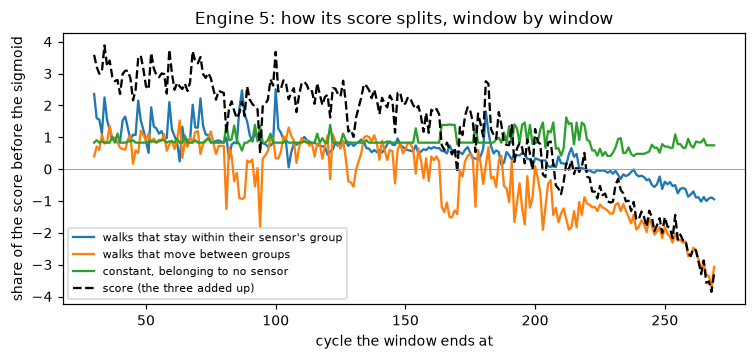

Largest miss of stays + moves + constant against the score: 2.7e-15


,stays,moves,constant,score,"prediction, cycles"
first third,1.158,0.604,0.887,2.649,115.403
middle third,0.671,0.218,0.911,1.799,104.891
last third,-0.151,-1.618,0.835,-0.934,41.706


In [7]:
life = walk_relevance(model, held_back.features[engine_rows])
life_parts = crossing_relevance(life, sensors, pool=groups)
cycles = held_back.end_cycles[engine_rows]

figure, axis = plt.subplots(figsize=(8, 3.2))
axis.plot(cycles, life_parts["stays"], label="walks that stay within their sensor's group")
axis.plot(cycles, life_parts["moves"], label="walks that move between groups")
axis.plot(cycles, life_parts["constant"], label="constant, belonging to no sensor")
axis.plot(cycles, life_parts["score"], "k--", label="score (the three added up)")
axis.axhline(0, color="0.6", linewidth=0.6)
axis.set_xlabel("cycle the window ends at")
axis.set_ylabel("share of the score before the sigmoid")
axis.legend(fontsize=7, loc="lower left")
axis.set_title(f"Engine {engine}: how its score splits, window by window")
plt.show()
print(f"Largest miss of stays + moves + constant against the score: "
      f"{np.abs(life_parts['stays'] + life_parts['moves'] + life_parts['constant'] - life_parts['score']).max():.1e}")
thirds = np.array_split(np.arange(len(cycles)), 3)
display(pd.DataFrame({
    name: [life_parts[column].iloc[rows].mean() for rows in thirds]
    for name, column in (("stays", "stays"), ("moves", "moves"), ("constant", "constant"),
                         ("score", "score"), ("prediction, cycles", "predicted"))
}, index=["first third", "middle third", "last third"]).round(3))

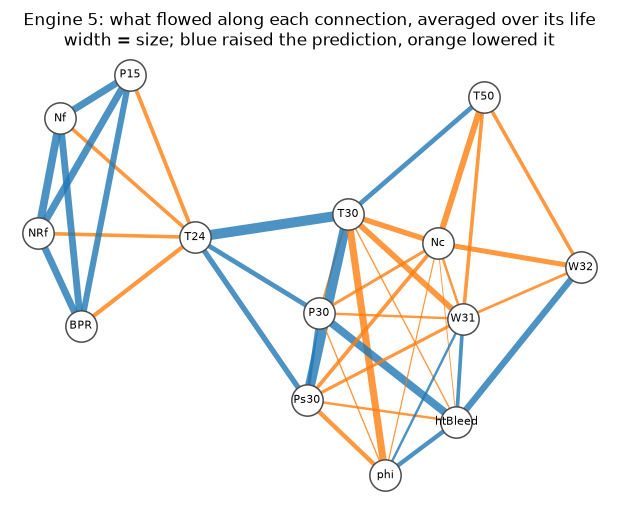

Largest average flows, both directions added, score units:


,flow
T24-T30,0.2259
T30-Ps30,0.2224
Nf-NRf,0.1701
P30-htBleed,0.1695
T30-phi,-0.1532
P15-NRf,0.1523
P15-Nf,0.1503
NRf-BPR,0.1478


In [8]:
flow = connection_relevance(life, sensors, pool=groups).mean(axis=0)
graph = to_networkx(prepared.adjacency_raw, sensors)
place = nx.kamada_kawai_layout(graph)
pairs = connections_of(prepared.adjacency_raw)
values = np.array([flow[i, j] + flow[j, i] for i, j in pairs])
peak = np.abs(values).max()

figure, axis = plt.subplots(figsize=(7, 5.2))
for (i, j), value in zip(pairs, values):
    (x1, y1), (x2, y2) = place[sensors[i]], place[sensors[j]]
    axis.plot([x1, x2], [y1, y2], color="tab:blue" if value >= 0 else "tab:orange",
              linewidth=0.6 + 6 * abs(value) / peak, alpha=0.8, zorder=1)
for name, (x, y) in place.items():
    axis.scatter([x], [y], s=420, color="white", edgecolors="0.3", zorder=2)
    axis.text(x, y, name, ha="center", va="center", fontsize=7, zorder=3)
axis.set_title(f"Engine {engine}: what flowed along each connection, averaged over its life\n"
               "width = size; blue raised the prediction, orange lowered it")
axis.axis("off")
plt.show()
flows = pd.Series(values, index=[f"{sensors[i]}-{sensors[j]}" for i, j in pairs])
print("Largest average flows, both directions added, score units:")
display(flows.reindex(flows.abs().sort_values(ascending=False).index).head(8).round(4).to_frame("flow"))

#### Reading the figures

The score falls from 2.649 on average in the first third of the engine's life to −0.934 in the last third, and the prediction from 115.403 to 41.706 cycles. The constant hardly moves (0.887, 0.911, 0.835), so the fall comes from the walks, and mostly from walks that move between groups, which go from +0.604 to −1.618; walks that stay within a group go from +1.158 to −0.151.

On the graph, averaged over the whole life, the widest connections are T24–T30 (+0.2259) and T30–Ps30 (+0.2224), then the links inside the group P15, Nf, NRf and BPR; T30–phi is the largest that lowered the prediction (−0.1532). An average over a life mixes early windows, where shares are mostly positive, with late ones, where they turn negative, so a thin line can hide two large contributions of opposite sign.

### Step 4 — What flowed along a connection, beside what removing it does

**What.** For the same windows, remove each of the 41 connections in turn from the raw graph, rescale the graph as the network's own was made, and run the same network again, without retraining (assumption A-30). Set the average size of each removal's effect, in cycles, beside the average size of what flowed along that connection.

**Why.** "The connections that matter most" can mean either. If the two measures ranked the connections alike, the distinction would not matter here.

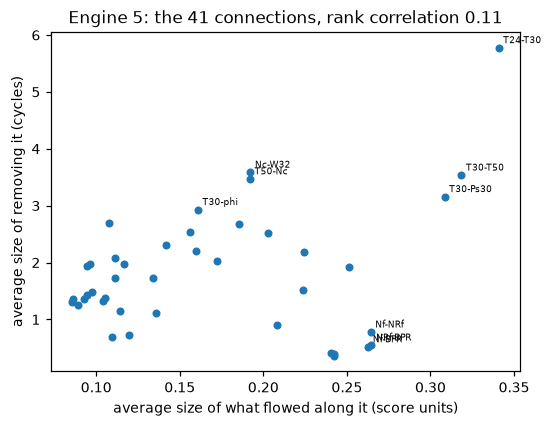

Rank correlation between flow and removal over the 41 connections: 0.11
Largest average removal effects, cycles:


,removal
T24-T30,5.78
Nc-W32,3.59
T30-T50,3.54
T50-Nc,3.47
T30-Ps30,3.16
T30-phi,2.93


In [9]:
removal = connection_removal(model, held_back.features[engine_rows], prepared.adjacency_raw,
                             sensors, method=prepared.config.adjacency_normalization)
flow_size = np.abs(np.stack([
    connection_relevance(life, sensors, pool=groups)[:, i, j]
    + connection_relevance(life, sensors, pool=groups)[:, j, i] for i, j in pairs
], axis=1)).mean(axis=0)
removal_size = removal.abs().mean(axis=0).to_numpy()
agreement = stats.spearmanr(flow_size, removal_size).statistic

figure, axis = plt.subplots(figsize=(5.5, 4))
axis.scatter(flow_size, removal_size, s=18)
for name, x, y in zip(removal.columns, flow_size, removal_size):
    if y > np.quantile(removal_size, 0.85) or x > np.quantile(flow_size, 0.85):
        axis.annotate(name, (x, y), fontsize=6, xytext=(3, 3), textcoords="offset points")
axis.set_xlabel("average size of what flowed along it (score units)")
axis.set_ylabel("average size of removing it (cycles)")
axis.set_title(f"Engine {engine}: the 41 connections, rank correlation {agreement:.2f}")
plt.show()
print(f"Rank correlation between flow and removal over the 41 connections: {agreement:.2f}")
print("Largest average removal effects, cycles:")
display(removal.abs().mean().sort_values(ascending=False).head(6).round(2).to_frame("removal"))

#### Reading the figure

On this engine the two measures rank the 41 connections almost independently: a rank correlation of 0.11. Removing T24–T30 moves the prediction most, by 5.78 cycles on average, and it also carries the largest flow. But the next three largest removal effects — Nc–W32 (3.59), T30–T50 (3.54) and T50–Nc (3.47) — are on connections outside the eight largest flows. Removal also rescales the rest of both sensors' rows, and a removal touching one of the three groups makes its members differ, so it measures something else (assumption A-30). "The connections that matter most" therefore has to say which of the two it means.

### Step 5 — The measurement over five seeds

**What.** The numbers above are one seed. `scripts/measure_walks.py` repeated the measurement on the last window of every test engine for all five saved seeds, and explained, beside each trained network, an untrained one built from the same seed exactly as training builds it — the trained network's own starting point. This cell reads its stored result rather than recomputing it.

**Why.** Much of what a walk share says is fixed by the graph's own weights before any training: a sensor's connection to itself weighs one over its number of connections plus one. A figure says something about training only where the trained and untrained networks differ.

In [10]:
folders = sorted((run.path / "walks").glob("*/summary.json"))
if not folders:
    raise FileNotFoundError(
        f"{run.name} has no walks/ folder. Make one with\n\n"
        f"    python scripts/measure_walks.py --run {run.name}\n"
    )
measured = json.loads(folders[-1].read_text(encoding="utf-8"))
per_seed = pd.read_csv(folders[-1].parent / "per_seed.csv")
print(f"Measured at {measured['commit']} on {measured['finished_utc']}, seeds {measured['seeds']}")
columns = {"stays_share_median": "walks staying within a group, share of size",
           "constant_share_median": "constant, share of the score's size",
           "cancellation_median": "walk sizes / size of their sum",
           "removal_agreement": "flow against removal, rank correlation"}
table = per_seed.groupby("network")[list(columns)].agg(["mean", "std"]).T.unstack()
table.index = [columns[i] for i in table.index]
display(table.round(3))
paired = {key: stats.ttest_rel(per_seed[per_seed.network == "trained"].sort_values("seed")[key],
                               per_seed[per_seed.network == "untrained"].sort_values("seed")[key]).pvalue
          for key in columns}
print("Paired over seeds, trained against untrained, p:", {columns[k]: round(v, 3) for k, v in paired.items()})

Measured at 14c1d64-dirty on 20260926T160933Z, seeds [42, 43, 44, 45, 46]


network                                     trained        untrained       
                                               mean    std      mean    std
walks staying within a group, share of size   0.055  0.030     0.154  0.037
constant, share of the score's size           0.510  0.037     0.816  0.141
walk sizes / size of their sum                8.586  3.488     8.186  5.208
flow against removal, rank correlation       -0.156  0.201     0.424  0.247

Paired over seeds, trained against untrained, p: {'walks staying within a group, share of size': np.float64(0.023), "constant, share of the score's size": np.float64(0.009), 'walk sizes / size of their sum': np.float64(0.847), 'flow against removal, rank correlation': np.float64(0.009)}


#### What the five seeds say

Over the five seeds, on the last window of every test engine: walks that stay within a group hold 5.5 ± 3.0 % of the walk size in the trained networks, against 15.4 ± 3.7 % in their untrained starting points (paired p = 0.023); the constant is 51 ± 4 % of the score's size, against 82 ± 14 % (p = 0.009); the walks cancel about equally before and after training (8.6 against 8.2, p = 0.85); and flow and removal rank the connections in unrelated orders after training (−0.16 ± 0.20), where before training they agreed moderately (0.42 ± 0.25, p = 0.009). Seed 42's engine above, at 0.11, is one of these networks on one engine. The log records the same measurement for four other configurations (assumptions A-29 and A-30).

## 5. What walks do and do not show

1. **What object is explained?** One window's score before the sigmoid.
2. **What does the method have access to?** Every weight, the sensor graph, and which ReLUs are on at that window. It is specific to this kind of network.
3. **What does it change?** Nothing. No input is replaced and no connection is removed.
4. **What does it measure?** How the network's own arithmetic, at that window, divides the score among routes through the graph.
5. **What is the result?** One share per walk — 38,416 per window, 5,178 of them possible on the paper's graph — which add up, with a constant no sensor owns, to the score. They can be added up by starting sensor, by connection, or into walks that stay and walks that move.
6. **What does it assume?** That holding the ReLUs as the window set them describes the network there, and that a number's share is the number times its effect. The graph layers' ReLUs stay as they are for any positive scaling of the input, so only the last layers' ReLUs make this local.
7. **What does it not show?**
   - **What removing a connection would do.** Step 4 shows the two can rank connections quite differently.
   - **That the graph is useful.** Walks describe one trained network; comparing graphs needs retraining.
   - **Anything causal about engines**, or cycles: the shares are parts of the score.

**Do not confuse** a large walk share with an important connection: shares are large and cancel, and they are partly fixed by the graph's own weights before training.

## 6. Final verification

In [11]:
checks = [
    ("The loaded network scores what the run recorded", same_network, f"seed {SEED}"),
    ("Walks plus constant give the score on the worked window", adds_up,
     f"{conservation_error(result):.1e}"),
    ("Each sensor's total equals the gradient check", matches_gradient, "14 sensors"),
    ("The score through the sigmoid is the prediction", turns_into_prediction, f"engine {engine}"),
    ("Walks plus constant give the score at every window", bool(conservation_error(life) < 1e-9),
     f"{conservation_error(life):.1e} over {len(engine_rows)} windows"),
]
width = max(len(name) for name, _, _ in checks) + 2
print(f"{'CHECK':<{width}} RESULT   DETAIL")
print("-" * (width + 40))
for name, passed, detail in checks:
    print(f"{name:<{width}} {'PASS' if passed else 'FAIL':<8} {detail}")
print("-" * (width + 40))
failed = [name for name, passed, _ in checks if not passed]
if failed:
    raise AssertionError(f"{len(failed)} check(s) failed: {failed}")
print(f"All {len(checks)} checks passed.")

CHECK                                                     RESULT   DETAIL
-------------------------------------------------------------------------------------------------
The loaded network scores what the run recorded           PASS     seed 42
Walks plus constant give the score on the worked window   PASS     4.4e-16
Each sensor's total equals the gradient check             PASS     14 sensors
The score through the sigmoid is the prediction           PASS     engine 5
Walks plus constant give the score at every window        PASS     2.7e-15 over 240 windows
-------------------------------------------------------------------------------------------------
All 5 checks passed.


## 7. Summary

### What this notebook produced

- **Walk shares** for one window, checked against the score, against PyTorch's own differentiation and against the network's prediction.
- **The engine's whole life**: what stays within a group and what moves, and what flowed along each connection of the graph.
- **Flow beside removal** for the 41 connections, and the stored five-seed measurement with each network's untrained starting point.

### Decisions that were not read from the paper

| Decision | Value used | Written up as |
|---|---|---|
| Explaining walks at all | GNN-LRP, not in the paper, on the score before the sigmoid, with its setting gamma at 0 | A-29 |
| Sensors the graph cannot tell apart | counted as one wherever a walk ends | A-29 |
| What removing a connection means | deleted from the raw graph both ways, graph rescaled, network not retrained | A-30 |
| Which engine is followed over its life | the held-back engine with the most windows, as in the other notebooks | this notebook |

### References

- Schnake, T., Eberle, O., Lederer, J., Nakajima, S., Schütt, K. T., Müller, K.-R., & Montavon, G. (2022). Higher-order explanations of graph neural networks via relevant walks. *IEEE Transactions on Pattern Analysis and Machine Intelligence*, 44(11), 7581-7596.